# Portas quânticas com PennyLane e QuTiP

Neste notebook:

- PennyLane é usado para construir os circuitos;
- QuTiP é usado para plotar a esfera de Bloch;
- os exemplos são mantidos simples e diretos.


## Preparação


In [4]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

from qutip import Bloch, Qobj


## Função auxiliar para a esfera de Bloch


In [2]:
def plot_bloch_state(state, title):
    state = np.asarray(state, dtype=complex)
    ket = Qobj(state.reshape((2, 1)))

    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(111, projection="3d")

    b = Bloch(fig=fig, axes=ax)
    b.add_states(ket)
    b.render()

    ax.set_title(title, pad=20)
    plt.show()

# Portas de um qubit


## Porta X

A porta X troca:

\[
|0\rangle \leftrightarrow |1\rangle
\]


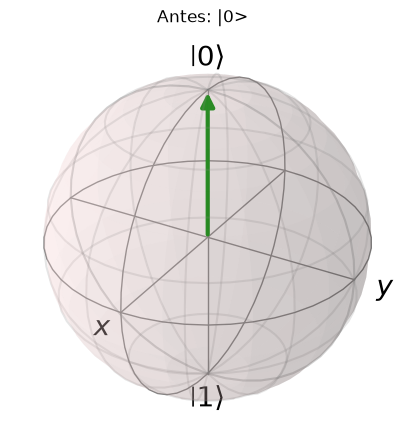

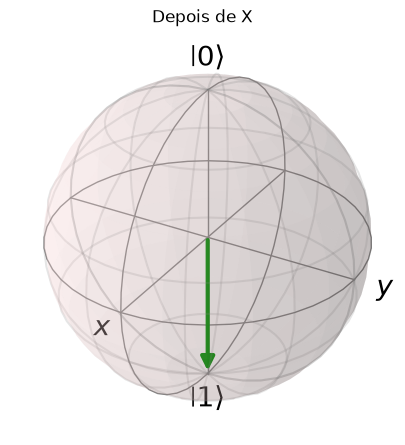

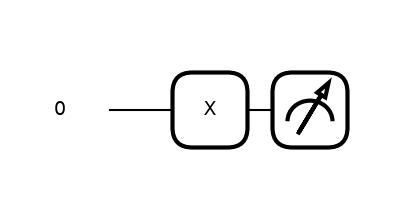

In [5]:
dev = qml.device("default.qubit", wires=1)

@qml.qnode(dev)
def circuito_x():
    qml.PauliX(wires=0)
    return qml.state()

estado_antes = np.array([1, 0], dtype=complex)
estado_depois = circuito_x()

plot_bloch_state(estado_antes, "Antes: |0>")
plot_bloch_state(estado_depois, "Depois de X")

qml.draw_mpl(circuito_x)()
plt.show()


## Porta Y

A porta Y também troca \(|0\rangle\) e \(|1\rangle\), mas introduz fase complexa.


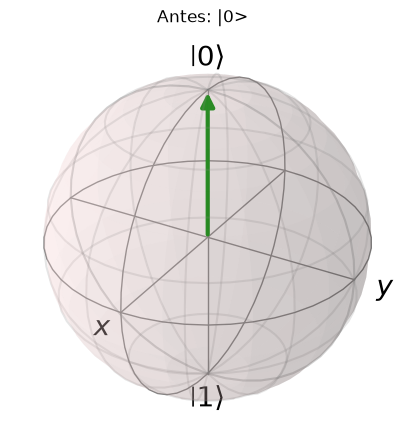

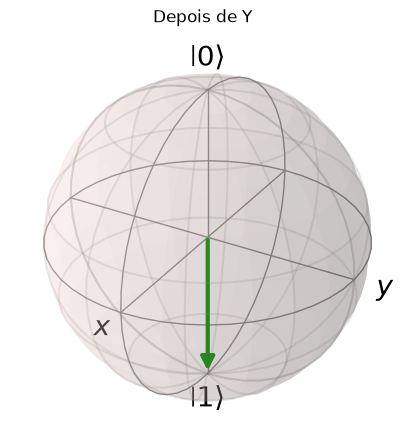

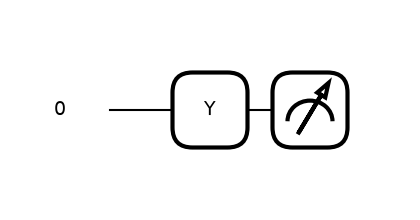

In [17]:
@qml.qnode(dev)
def circuito_y():
    qml.PauliY(wires=0)
    return qml.state()

estado_antes = np.array([1, 0], dtype=complex)
estado_depois = circuito_y()

plot_bloch_state(estado_antes, "Antes: |0>")
plot_bloch_state(estado_depois, "Depois de Y")

qml.draw_mpl(circuito_y)()
plt.show()


## Porta Z

A porta Z altera a fase relativa.

Para visualizar melhor o efeito, usamos como entrada:

\[
|+\rangle
=
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
\]


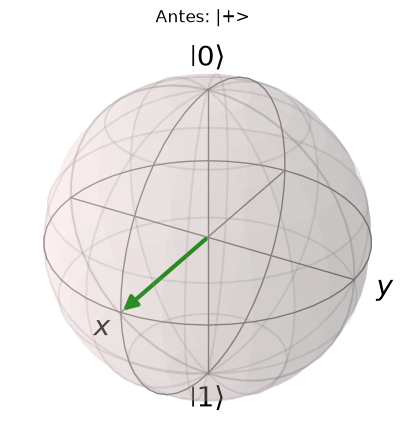

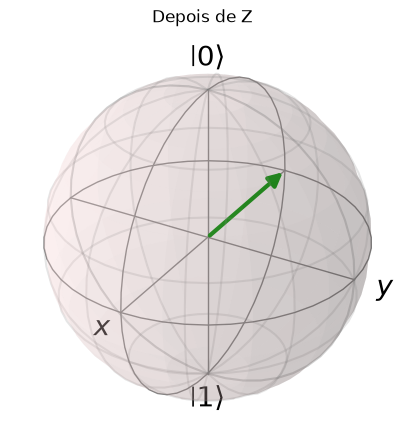

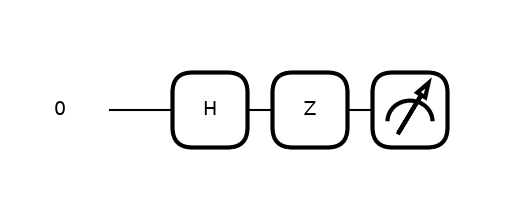

In [18]:
@qml.qnode(dev)
def antes_z():
    qml.Hadamard(wires=0)
    return qml.state()

@qml.qnode(dev)
def circuito_z():
    qml.Hadamard(wires=0)
    qml.PauliZ(wires=0)
    return qml.state()

estado_antes = antes_z()
estado_depois = circuito_z()

plot_bloch_state(estado_antes, "Antes: |+>")
plot_bloch_state(estado_depois, "Depois de Z")

qml.draw_mpl(circuito_z)()
plt.show()


## Porta Hadamard

A porta Hadamard transforma:

\[
|0\rangle
\longrightarrow
|+\rangle
=
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
\]


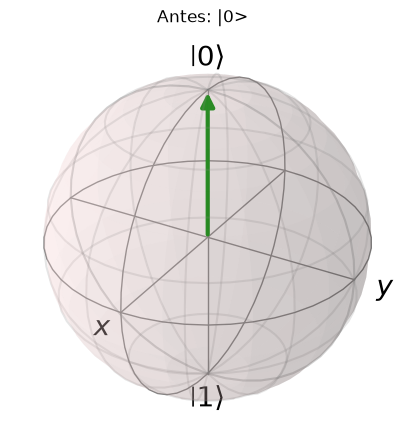

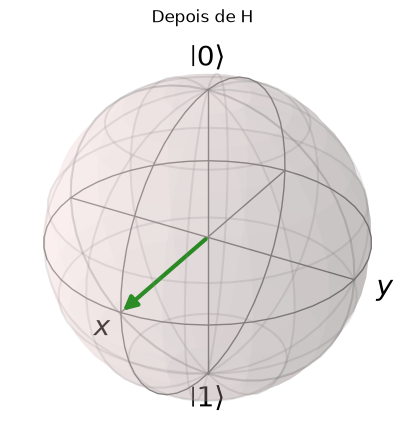

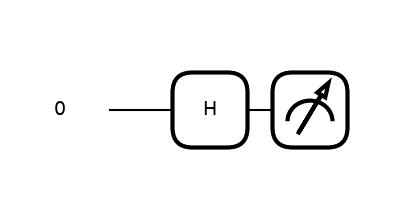

In [19]:
@qml.qnode(dev)
def circuito_h():
    qml.Hadamard(wires=0)
    return qml.state()

estado_antes = np.array([1, 0], dtype=complex)
estado_depois = circuito_h()

plot_bloch_state(estado_antes, "Antes: |0>")
plot_bloch_state(estado_depois, "Depois de H")

qml.draw_mpl(circuito_h)()
plt.show()


# Portas de dois qubits


## Porta CNOT

A porta CNOT possui:

- um qubit de controle;
- um qubit alvo.

Exemplo:

\[
|10\rangle
\longrightarrow
|11\rangle
\]


In [1]:
dev2 = qml.device("default.qubit", wires=2)

@qml.qnode(dev2)
def circuito_cnot():
    qml.CNOT(wires=[0, 1])
    return qml.state()

estado_final = circuito_cnot()

print("Estado final:", estado_final)

qml.draw_mpl(circuito_cnot)()
plt.show()


NameError: name 'qml' is not defined

### Esferas de Bloch da CNOT

Antes:

- qubit 0 em \(|1\rangle\);
- qubit 1 em \(|0\rangle\).

Depois:

- qubit 0 continua em \(|1\rangle\);
- qubit 1 passa para \(|1\rangle\).


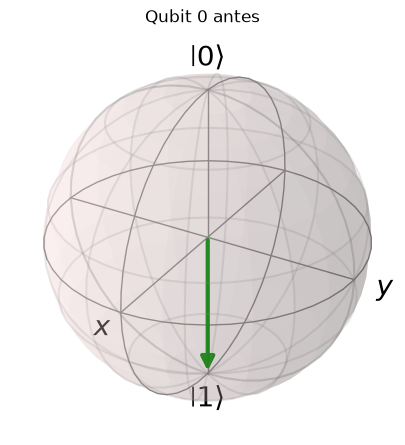

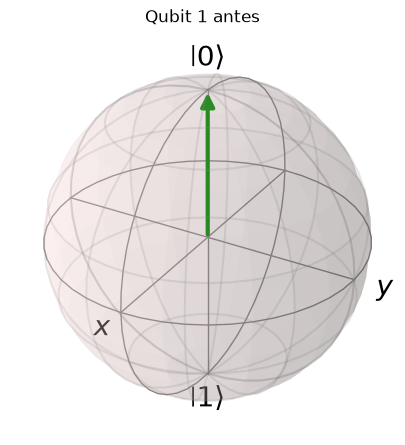

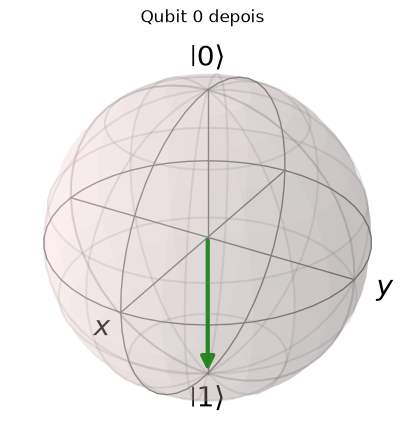

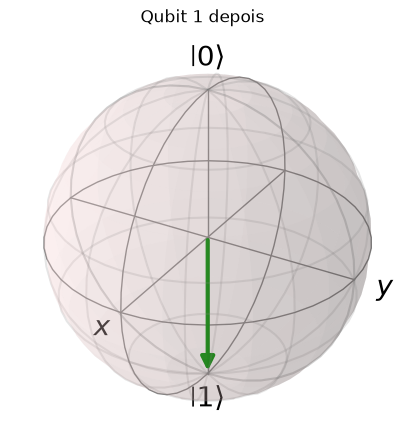

In [21]:
q0_antes = np.array([0, 1], dtype=complex)
q1_antes = np.array([1, 0], dtype=complex)

q0_depois = np.array([0, 1], dtype=complex)
q1_depois = np.array([0, 1], dtype=complex)

plot_bloch_state(q0_antes, "Qubit 0 antes")
plot_bloch_state(q1_antes, "Qubit 1 antes")

plot_bloch_state(q0_depois, "Qubit 0 depois")
plot_bloch_state(q1_depois, "Qubit 1 depois")


## Porta SWAP

A porta SWAP troca os estados dos dois qubits.

Exemplo:

\[
|10\rangle
\longrightarrow
|01\rangle
\]


Estado final: [0.+0.j 1.+0.j 0.+0.j 0.+0.j]


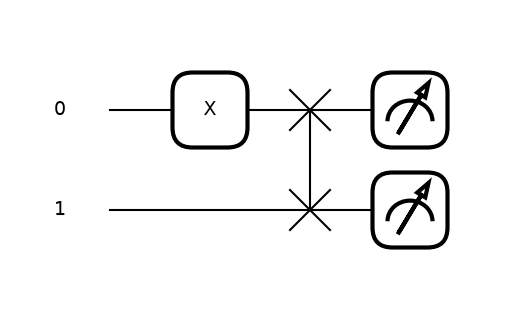

In [ ]:
@qml.qnode(dev2)
def circuito_swap():
    qml.SWAP(wires=[0, 1])
    return qml.state()

estado_final = circuito_swap()

print("Estado final:", estado_final)

qml.draw_mpl(circuito_swap)()
plt.show()


### Esferas de Bloch da SWAP

Antes:

- qubit 0 em \(|1\rangle\);
- qubit 1 em \(|0\rangle\).

Depois:

- qubit 0 em \(|0\rangle\);
- qubit 1 em \(|1\rangle\).


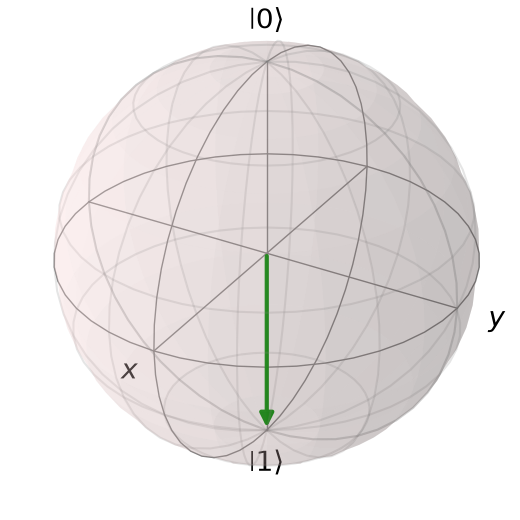

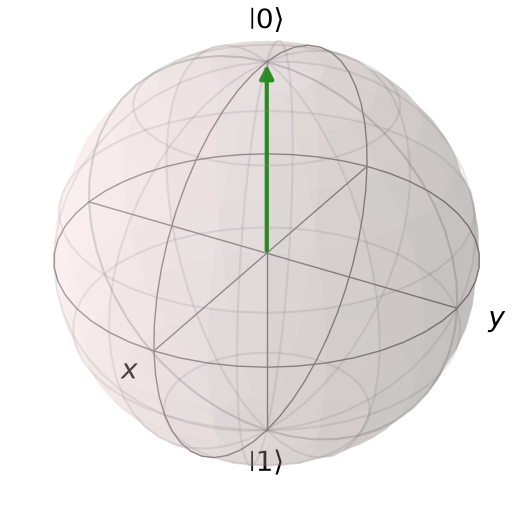

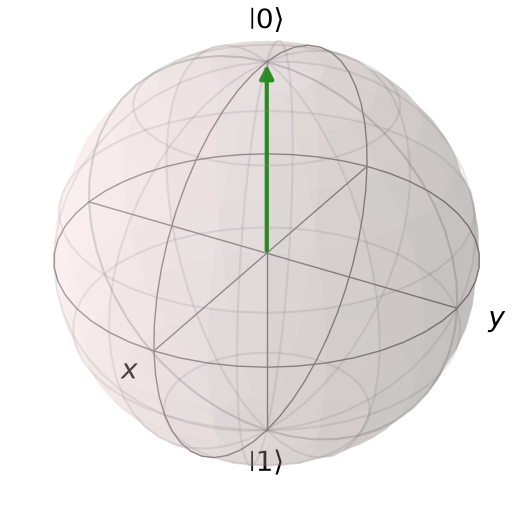

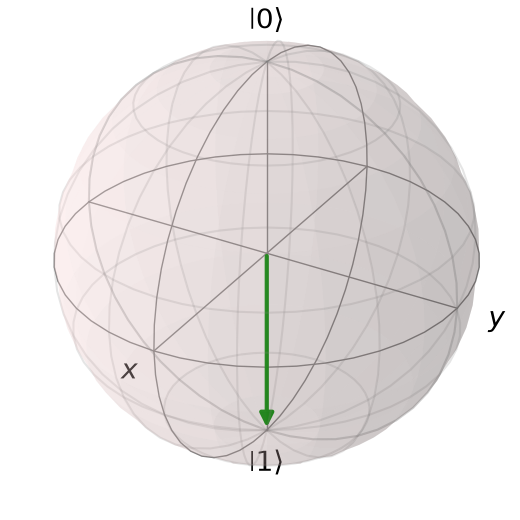

In [14]:
q0_antes = np.array([0, 1], dtype=complex)
q1_antes = np.array([1, 0], dtype=complex)

q0_depois = np.array([1, 0], dtype=complex)
q1_depois = np.array([0, 1], dtype=complex)

plot_bloch_state(q0_antes, "Qubit 0 antes")
plot_bloch_state(q1_antes, "Qubit 1 antes")

plot_bloch_state(q0_depois, "Qubit 0 depois")
plot_bloch_state(q1_depois, "Qubit 1 depois")


# Resumo

## Portas de um qubit

- X
- Y
- Z
- Hadamard

## Portas de dois qubits

- CNOT
- SWAP
